# Econ 5200 PS2 — The Underpowered Portfolio

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 5-8 · 100 points · your role: Experimentation lead, consulting engagement

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is experimentation lead's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning.

## Setup

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: Reconstruct the Portfolio (30 pts)

### Step 1.1: Simulate the experiment programme (15 pts)

In [11]:
n_experiments = 200
share_succ = 0.25
succ_mean = 0.65
succ_sd = 0.2
normal_mean = 0
normal_sd = 0.04
tests_sd = 20
zero_cutoff = 0.1
rev_min, rev_max = 1000, 100000

is_real = rng.random(size=n_experiments) < share_succ

succ_draw = rng.normal(succ_mean, succ_sd, size=n_experiments)
norm_draw = rng.normal(normal_mean, normal_sd, size=n_experiments)
true_effects = np.where(is_real, succ_draw, norm_draw)

n_tested = np.exp(rng.uniform(np.log(rev_min), np.log(rev_max), size=n_experiments))
n_tested = n_tested.round().astype(int)

se = tests_sd * np.sqrt(2 / n_tested)
observed = true_effects + rng.normal(0, se)
z = observed / se
p_val = 2 * stats.norm.sf(np.abs(z))

test_dict = {'test': np.arange(1, n_experiments + 1),
             'is_real': is_real,
             'true_effects': true_effects,
             'n_tested': n_tested,
             'se': se,
             'observed': observed,
             'z': z,
             'p_val': p_val,}
df_tests = pd.DataFrame(test_dict)

print(df_tests)

print("share truly near zero:", (np.abs(df_tests['true_effects']) < zero_cutoff).mean().round(4))

     test  is_real  true_effects  n_tested     se  observed      z      p_val
0       1    False         0.030      9537  0.290    -0.332 -1.145  2.521e-01
1       2    False         0.009     93558  0.092     0.056  0.610  5.416e-01
2       3    False         0.021      8510  0.307     0.141  0.460  6.452e-01
3       4    False        -0.028     90330  0.094    -0.196 -2.086  3.696e-02
4       5     True         0.718      6655  0.347     0.675  1.947  5.156e-02
..    ...      ...           ...       ...    ...       ...    ...        ...
195   196     True         0.661     57645  0.118     0.495  4.206  2.604e-05
196   197    False         0.073     11814  0.260     0.159  0.611  5.412e-01
197   198    False        -0.066     17522  0.214    -0.131 -0.612  5.407e-01
198   199     True         0.790      3519  0.477     0.560  1.175  2.400e-01
199   200    False        -0.017      1262  0.796     0.676  0.849  3.957e-01

[200 rows x 8 columns]
share truly near zero: 0.75


*The Experiment*

The company that we are looking at is a food delivery company that runs around 200 A/B tests every year on app changes, such as the locations of buttons, colouring and more. In one example, the control group sees the regular interface, with a "manage order" section and a list menu to add items to an order that has already been placed, while the treatment group gets a large red button with the text `add items free of delivery` underneath it.

We are measuring revenue per order, and the effect is the difference in revenue per order between the treatment and control groups. Only 25% of the ideas tested have a real effect, drawn from `Normal(mean $0.65, SD $0.20)`, while the other 75% have essentially no effect, drawn from `Normal(mean $0, SD $0.04)`. An effect counts as essentially zero when `|effect| < $0.10`, and 75% of the 200 true effects fall within that cutoff. Lastly, the outcome has an SD of $20 per order, and each test has between 1,000 and 100,000 customers per group, drawn on a log-uniform scale.

### Step 1.2: Apply the client's rule (15 pts)

In [12]:
df_tests['shipped'] = (df_tests['p_val'] < 0.05) & (df_tests['observed'] > 0)

n_shipped = df_tests['shipped'].sum()
share_shipped = df_tests['shipped'].mean()
print('shipped:', n_shipped, 'of', len(df_tests), f"({share_shipped:.1%})")

df_shipped = df_tests[df_tests['shipped']]

fake_ship = (np.abs(df_shipped['true_effects']) < zero_cutoff).mean()
print("shipped features that really don't have an effect:", f"{fake_ship:.1%}")

mean_true = df_shipped['true_effects'].mean()
mean_obs = df_shipped['observed'].mean()

print(f"mean true: {mean_true:.3f}   mean observed: {mean_obs:.3f}")
print(f"observed / true: {mean_obs / mean_true:.2f}x")


shipped: 28 of 200 (14.0%)
shipped features that really don't have an effect: 7.1%
mean true: 0.583   mean observed: 0.730
observed / true: 1.25x


*Client's rule*

We now label which tests actually ended up being shipped. The condition here is that the estimated effect was positive and that the p-value was below 0.05. I added the positive condition because we don't want to ship changes that generate less revenue, which would be sub-optimal for the business. Under this rule we ship 14% of the features, which is very close to the client's 15%, and that 14% is 28 shipped features. Of those 28, 2 don't actually have a real effect, making up 7.1% of the shipped features. The true mean of the shipped features is $0.58, against an estimated mean of $0.73, which makes the estimate 1.25x too high. This is the winner's curse: the client books a $0.73 increase per order despite the real effect being only $0.58.

## Phase 2: The Winner's Curse (35 pts)

### Step 2.1: Quantify the exaggeration (20 pts)

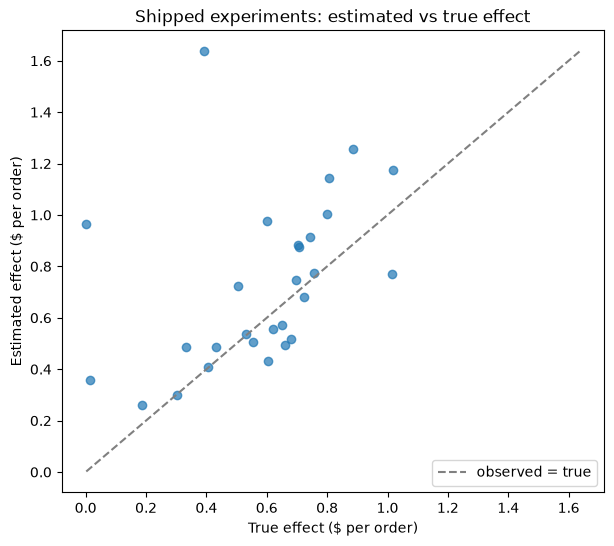

         n  mean_true  mean_obs  inflation
tier                                      
low      1      0.393     1.636      4.168
medium   6      0.561     0.933      1.664
high    21      0.599     0.628      1.050


In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(df_shipped['true_effects'], df_shipped['observed'], alpha=0.7)

lo = min(df_shipped['true_effects'].min(), df_shipped['observed'].min())
hi = max(df_shipped['true_effects'].max(), df_shipped['observed'].max())
ax.plot([lo, hi], [lo, hi], "--", color="gray", label="observed = true")

ax.set_xlabel("True effect ($ per order)")
ax.set_ylabel("Estimated effect ($ per order)")
ax.set_title("Shipped experiments: estimated vs true effect")
ax.legend()
plt.show()

reference = succ_mean
df_tests['power'] = stats.norm.cdf(reference / df_tests['se'] - 1.96)

df_tests['tier'] = pd.qcut(df_tests['power'], 3, labels=["low", "medium", "high"])
df_shipped = df_tests[df_tests['shipped']]

tier_table = df_shipped.groupby('tier', observed=False).agg(
    n=('true_effects', 'size'),
    mean_true=('true_effects', 'mean'),
    mean_obs=('observed', 'mean'),
)
tier_table['inflation'] = tier_table['mean_obs'] / tier_table['mean_true']
print(tier_table)

*Exaggeration*

Most of the points on the scatter plot lie above the diagonal line. This means that most of the shipped experiments have an exaggerated effect, which we already saw with the 1.25x overestimate in Step 1.2. We can also see that the inflation decreases as the power of the experiment rises, but there is only one experiment in the low-power tier, which makes that tier very susceptible to noise. A test ships only when it clears the significance line, so among the shipped tests the noise ran upward. A low-powered test has a high SE, so its line sits far above its true effect, and it can only ship with a very large overestimate, which makes it the most inflated. A high-powered test doesn't need this luck, which means that its estimate sits much closer to the truth. For my work, the power definition was the power to detect the typical real effect, which is $0.65, computed from each test's SE as `Φ($0.65 ÷ SE − 1.96)` and then split into thirds.

### Step 2.2: The bootstrap where the formula fails (15 pts)

realized returns: 16.33   book total: 20.43
loop SE: 3.16   percentile 95% CI: [10.51, 22.82]
scipy SE: 3.14   BCa 95% CI: [10.87, 23.39]
distinct bootstrap values: 9995 of 10000


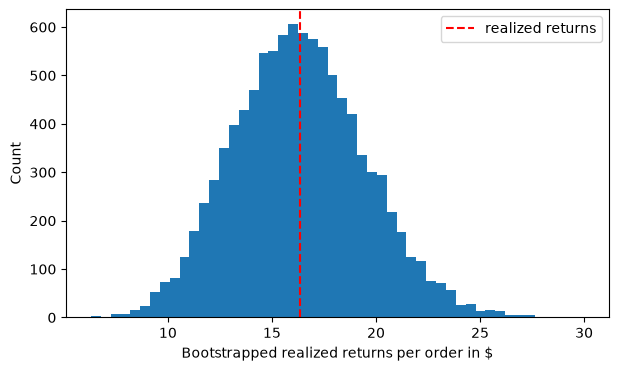

In [14]:
df_tests['realized'] = np.where(df_tests['shipped'], df_tests['true_effects'], 0.0)
realized_return = df_tests['realized'].sum()
book_total = df_tests.loc[df_tests['shipped'], 'observed'].sum()
print(f"realized returns: {realized_return:.2f}   book total: {book_total:.2f}")

values = df_tests['realized'].values
n = len(values)
boot_sums = []
for _ in range(10_000):
    i = rng.integers(0, n, size=n)
    boot_sums.append(values[i].sum())
boot_sums = np.array(boot_sums)

se_loop = np.std(boot_sums, ddof=1)
ci_pct = np.percentile(boot_sums, [2.5, 97.5])
print(f"loop SE: {se_loop:.2f}   percentile 95% CI: [{ci_pct[0]:.2f}, {ci_pct[1]:.2f}]")

res = stats.bootstrap((values,), np.sum, n_resamples=10_000, method='BCa', random_state=rng)
ci = res.confidence_interval
print(f"scipy SE: {res.standard_error:.2f}   BCa 95% CI: [{ci.low:.2f}, {ci.high:.2f}]")

print("distinct bootstrap values:", len(np.unique(boot_sums.round(6))), "of", len(boot_sums))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(boot_sums, bins=50)
ax.axvline(realized_return, color='red', linestyle='--', label='realized returns')
ax.set_xlabel('Bootstrapped realized returns per order in $')
ax.set_ylabel('Count')
ax.legend()
plt.show()


*Bootstrap*

Realized returns are the sum of the true effects of the shipped tests. Because of this, the number of shipped tests and which tests ship are both random, so there is no easy formula for the SE, so instead I resampled the 200 experiments with replacement 10,000 times. The result is $16.33, with a BCa 95% CI of [$10.87, $23.39]. My own loop gives an SE of 3.16, while scipy gives 3.14, which is close enough to call it a match. The client booked $20.43, but the true return is around 20% lower, which puts the booked figure near the top of the interval. I also checked whether the bootstrap is degenerate, and it isn't, as it has 9,995 distinct values out of 10,000, so it doesn't run into the same problem as Lab 07. We also have a small sample, since only 28 shipped tests drive the sum, so I report the BCa interval, which shifts the interval slightly upward compared to the percentile one. Lastly, resampling the rows assumes that the experiments are independent, which they are through our artificial design. In reality, if tests were run on overlapping users, that could break this.

## Phase 3: A Rule They Can Adopt (25 pts)

### Step 3.1: Design the alternative (20 pts)

In [16]:
ref = succ_mean
n_needed = int(np.ceil(2 * (1.96 + 0.84) ** 2 * (tests_sd / ref) ** 2))

under = df_tests['power'] < 0.8

df_tests['n_new'] = np.where(under, n_needed, df_tests["n_tested"])
df_tests['se_new'] = tests_sd * np.sqrt(2 / df_tests['n_new'])
redraw = df_tests['true_effects'] + rng.normal(0, df_tests['se_new'])
df_tests['obs_new'] = np.where(under, redraw, df_tests['observed'])
df_tests['p_new'] = 2 * stats.norm.sf(np.abs(df_tests['obs_new'] / df_tests['se_new']))
df_tests['shipped_new'] = (df_tests['p_new'] < 0.05) & (df_tests['obs_new'] > 0)

def summarise(flag):
    picked = df_tests[flag]
    return {
        'shipped': int(flag.sum()),
        'true effect': picked['true_effects'].sum(),
        "false ship": (np.abs(picked['true_effects']) < zero_cutoff).mean(),
    }

comparison = pd.DataFrame({
    'p < 0.05 (client)': summarise(df_tests['shipped']),
    'power floor 80%': summarise(df_tests['shipped_new']),
})
print(comparison)
print("extra customers needed:", 2 * ((df_tests["n_new"] - df_tests['n_tested']).sum()))


             p < 0.05 (client)  power floor 80%
shipped                 28.000           43.000
true effect             16.329           26.418
false ship               0.071            0.070
extra customers needed: 2472204


*New rule*

Under this new rule, no test can launch until it has 80% power to detect the typical real effect, which is $0.65 per order. Any test below this is increased to the necessary size of 14,845 customers per group before it runs, while the ship rule itself stays the same. On the same 200 tests, the realized return rose from $16.33 to $26.42, summed over the shipped tests, which is about 62% more. Shipped tests also went from 28 to 43. Small tests were the issue before, shipping tests with inflated effects as well as missing real effects due to chance. But the most important thing is that this approach catches more real wins, and false negatives are a great hurt for a business. The big cost is the roughly 2.5 million extra customers needed to run these tests, and a firm might not always be able to collect data on this scale. Lastly, lowering the p-value threshold would lose even more realized return, as a false positive only brings about $0, so shipping one costs very little. The false-ship rate also changes from 7.1% to 7.0%, which means that they are around the same.

### Step 3.2: Ship the module (5 pts, its own rubric row)

The module the brief asks for. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [ ]:
%%writefile src/experiment_portfolio.py
"""Experiment-portfolio simulator and decision rules (ECON 5200 PS2)."""
from __future__ import annotations

import numpy as np
import pandas as pd
from scipy import stats


def simulate_portfolio(
    n: int,
    seed: int,
    share_succ: float = 0.25,
    succ_mean: float = 0.65,
    succ_sd: float = 0.2,
    normal_mean: float = 0.0,
    normal_sd: float = 0.04,
    tests_sd: float = 20.0,
    rev_min: int = 1000,
    rev_max: int = 100000,
) -> pd.DataFrame:
    """Return the experiment log with the true effect attached."""
    rng = np.random.default_rng(seed)
    is_real = rng.random(size=n) < share_succ

    succ_draw = rng.normal(succ_mean, succ_sd, size=n)
    norm_draw = rng.normal(normal_mean, normal_sd, size=n)
    true_effects = np.where(is_real, succ_draw, norm_draw)

    n_tested = np.exp(rng.uniform(np.log(rev_min), np.log(rev_max), size=n))
    n_tested = n_tested.round().astype(int)

    se = tests_sd * np.sqrt(2 / n_tested)
    observed = true_effects + rng.normal(0, se)
    z = observed / se
    p_val = 2 * stats.norm.sf(np.abs(z))

    log = pd.DataFrame({
        'test': np.arange(1, n + 1),
        'is_real': is_real,
        'true_effects': true_effects,
        'n_tested': n_tested,
        'se': se,
        'observed': observed,
        'z': z,
        'p_val': p_val,
    })
    log.attrs.update(seed=seed, succ_mean=succ_mean, tests_sd=tests_sd)
    return log


def apply_rule(log: pd.DataFrame, rule: str) -> pd.DataFrame:
    """Ship decisions under `rule`: the p < 0.05 threshold and at least one other."""
    out = log.copy()
    succ_mean = log.attrs['succ_mean']
    tests_sd = log.attrs['tests_sd']

    if rule == 'threshold':
        out['n_new'] = out['n_tested']
        out['se_new'] = out['se']
        out['obs_new'] = out['observed']
        out['p_new'] = out['p_val']
    elif rule == 'power_floor':
        rng = np.random.default_rng(log.attrs['seed'] + 1)
        out['power'] =

In [ ]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))
from src import experiment_portfolio as ep
# prove it runs: call the three functions on a small portfolio

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 7 for the AI row, 3 for the CFO memo)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The sequential design

In [ ]:
"""Always-valid sequential A/B test (Gaussian-mixture SPRT, Johari et al. 2017).
numpy + scipy only. Metric: revenue per order, known SD per arm = 20.
Effect = treatment mean - control mean.
"""
import numpy as np
from scipy.stats import norm

SIGMA = 20.0
LOOK_EVERY = 1000
ALPHA = 0.05


def msprt_stream(values, arms, sigma=SIGMA, tau=0.5, alpha=ALPHA,
                 look_every=LOOK_EVERY):
    """Stream of customers -> decision at each look.

    values : revenue per customer (dollars)
    arms   : 1 = treatment, 0 = control
    tau    : SD of N(0, tau^2) mixing prior on the effect (dollars); set it
             to the typical |true effect| in your portfolio.
    Returns a structured array, one row per look.
    """
    values, arms = np.asarray(values, float), np.asarray(arms, int)
    looks = np.arange(look_every, len(values) + 1, look_every)
    if len(values) % look_every:
        looks = np.append(looks, len(values))

    cs_t = np.cumsum(values * arms)[looks - 1]
    cs_c = np.cumsum(values * (1 - arms))[looks - 1]
    n_t = np.cumsum(arms)[looks - 1]
    n_c = looks - n_t
    ok = (n_t > 0) & (n_c > 0)

    diff = np.where(ok, cs_t / np.maximum(n_t, 1) - cs_c / np.maximum(n_c, 1), 0.0)
    V = np.where(ok, sigma**2 * (1 / np.maximum(n_t, 1) + 1 / np.maximum(n_c, 1)), np.inf)

    # Mixture likelihood ratio: integral of N(diff; theta, V) / N(diff; 0, V) over N(0, tau^2)
    log_lam = np.where(ok, 0.5 * np.log(V / (V + tau**2))
                       + tau**2 * diff**2 / (2 * V * (V + tau**2)), 0.0)
    p_av = np.minimum.accumulate(np.minimum(1.0, np.exp(-log_lam)))  # always-valid p
    reject = p_av <= alpha
    stop = np.cumsum(reject) > 0                                     # absorbing

    z = np.where(ok, diff / np.sqrt(V), 0.0)
    naive = np.cumsum(2 * norm.sf(np.abs(z)) <= alpha) > 0           # for comparison

    out = np.zeros(len(looks), dtype=[("look", int), ("n_seen", int), ("diff", float),
                                      ("se", float), ("log_lambda", float), ("p_always_valid", float),
                                      ("stop", bool), ("naive_stop", bool)])
    out["look"], out["n_seen"], out["diff"], out["se"] = np.arange(1, len(looks) + 1), looks, diff, np.sqrt(V)
    out["log_lambda"], out["p_always_valid"], out["stop"], out["naive_stop"] = log_lam, p_av, stop, naive
    return out


def simulate_stream(n_tested, effect, seed, sigma=SIGMA, base=50.0):
    rng = np.random.default_rng(seed)
    arms = rng.integers(0, 2, n_tested)
    values = base + effect * arms + rng.normal(0, sigma, n_tested)
    return values, arms


def null_fpr(n_tested_log, n_streams=1000, tau=0.5, seed0=0):
    """Run n_streams pure-null streams, sizes resampled from your log's n_tested."""
    rng = np.random.default_rng(seed0)
    sizes = rng.choice(np.asarray(n_tested_log), n_streams, replace=True)
    rej = np.zeros(n_streams, bool)
    naive = np.zeros(n_streams, bool)
    for i, n in enumerate(sizes):
        res = msprt_stream(*simulate_stream(int(n), 0.0, seed=seed0 + 1 + i), tau=tau)
        rej[i], naive[i] = res["stop"][-1], res["naive_stop"][-1]
    se = lambda p: np.sqrt(p * (1 - p) / n_streams)
    return {"msprt_fpr": rej.mean(), "msprt_se": se(rej.mean()),
            "naive_fpr": naive.mean(), "naive_se": se(naive.mean())}


if __name__ == "__main__":
    # Placeholder for your log's n_tested column (200 tests, 1k-100k).
    # Replace with: n_tested_log = log["n_tested"]
    n_tested_log = np.random.default_rng(42).integers(1, 101, 200) * 1000
    r = null_fpr(n_tested_log, n_streams=1000)
    print(f"mSPRT  FPR = {r['msprt_fpr']:.4f}  (SE {r['msprt_se']:.4f})")
    print(f"Naive  FPR = {r['naive_fpr']:.4f}  (SE {r['naive_se']:.4f})")

*Your answer here.*

### Task 4.2: The CFO memo

*Memo*

The wins recorded in our experiment are mostly real, but they are also overstated. Of the 28 tests that were shipped, 26 had an actual real effect, and the last 2 were tests inflated through a small sample size and chance. The team booked the realization at around 20 dollars, while the real one is closer to 16. This is the winner's curse: a test only ships when its noisy estimate clears the bar, so shipped estimates run high, worst in the smallest tests.

The current rule also, and more so, leaves a lot of money on the table. Most tests are too small to actually be able to detect a real effect, so many of the ideas that would generate an effect are left on the table. On the same set, a better policy would create an increase of 10 dollars per order of revenue generated.

The recommendation is to launch tests only with at least 80% power, in order to detect the necessary effect. This costs about 2.47 million extra test customers a year and keeps false wins at about 7%.

This only holds, though, if the effects are around 0.65 dollars. If they are any smaller, then the tests are underpowered again.

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

*Model and date:* 10/27 - Claude Opus 5.5

*Version 1 prompt:*

[Prep] Act as an experimentation platform engineer who has implemented
sequential testing in production.

[Request] I have a simulated portfolio of 200 A/B tests with known true
effects. Implement an always-valid sequential test -- a mixture
sequential probability ratio test or an alpha-spending boundary -- that
allows continuous monitoring without inflating the Type I error rate.
Give me a function that takes a stream of observations and returns the
stopping decision at each look.

[Iterate] numpy and scipy only. Reuse my log structure. The function
must be testable against a pure-null stream.

[Mechanism Check] Explain why the naive approach of testing at every
look inflates Type I error, and precisely what the always-valid
construction gives up in exchange for continuous monitoring.

[Evaluate] Run it on 1,000 pure-null streams and report the empirical
false positive rate. If it is not close to 5%, tell me what is wrong.

*Reply:*

*Version 2 prompt:*

[Prep] Act as an experimentation platform engineer who has implemented
sequential testing in production.

[Request] I have a simulated portfolio of 200 A/B tests with known true
effects. Implement an always-valid sequential test -- a mixture
sequential probability ratio test or an alpha-spending boundary -- that
allows continuous monitoring without inflating the Type I error rate.
Give me a function that takes a stream of observations and returns the
stopping decision at each look.

[Iterate] numpy and scipy only. Reuse my log structure. The function
must be testable against a pure-null stream.

What my data is: my tests measure revenue per order in dollars with an SD of 20; the effect is the treatment minus control.
Test size - each test is between 1000 and 100 000 customers, and my log has a column 'n_tested' with that size
Client checks- Client checks results after every 1000 customers.
How -> run 1000 test streams with my test sizes. Give each a different rng seed and get back and report false positive rates with its standard error


[Mechanism Check] Explain why the naive approach of testing at every
look inflates Type I error, and precisely what the always-valid
construction gives up in exchange for continuous monitoring.

[Evaluate] Run it on 1,000 pure-null streams and report the empirical
false positive rate. If it is not close to 5%, tell me what is wrong.

*Reply:*

## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted (the prior on effects and its parameters, the sample-size range, the seed, the ship rule), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [17]:
print('Truth and headline numbers')
print()
print('PLANTED PARAMETERS')
print('prior on effects:', f'{share_succ:.0%} real ~ N({succ_mean}, {succ_sd}), '
      f'{1 - share_succ:.0%} null ~ N({normal_mean}, {normal_sd})', '  set in Step 1.1')
print('sample-size range:', f'log-uniform {rev_min:,}–{rev_max:,} per group', '  set in Step 1.1')
print('outcome SD per order:', tests_sd, '  set in Step 1.1')
print('number of experiments:', n_experiments, '  set in Step 1.1')
print('near-zero cutoff:', zero_cutoff, '  set in Step 1.1')
print('seed:', 42, '  set in Setup')
print('ship rule:', 'p < 0.05 and observed > 0', '  Step 1.2')
print('alternative rule:', f'80% power to detect {succ_mean}', '  Step 3.1')
print()
print('MEMO NUMBERS')
print('share truly near zero:', f'{(np.abs(df_tests["true_effects"]) < zero_cutoff).mean():.4f}', '  Step 1.1')
print('shipped:', int(n_shipped), 'of', len(df_tests), f'({share_shipped:.4f})', '  Step 1.2')
print('false-ship rate:', f'{fake_ship:.4f}', '  Step 1.2')
print('mean true effect of shipped:', f'{mean_true:.2f}', '  Step 1.2')
print('mean observed effect of shipped:', f'{mean_obs:.2f}', '  Step 1.2')
print('inflation (observed / true):', f'{mean_obs / mean_true:.2f}x', '  Step 1.2')
print('ships by power tier:', tier_table['n'].to_dict(), '  Step 2.1')
print('inflation by power tier:', tier_table['inflation'].round(2).to_dict(), '  Step 2.1')
print('realised return:', f'{realized_return:.2f}', '  Step 2.2')
print('book total:', f'{book_total:.2f}', '  Step 2.2')
print('bootstrap SE (loop):', f'{se_loop:.2f}', '  Step 2.2')
print('percentile 95% CI:', f'[{ci_pct[0]:.2f}, {ci_pct[1]:.2f}]', '  Step 2.2')
print('bootstrap SE (scipy):', f'{res.standard_error:.2f}', '  Step 2.2')
print('BCa 95% CI:', f'[{ci.low:.2f}, {ci.high:.2f}]', '  Step 2.2')
print('distinct bootstrap values:', len(np.unique(boot_sums.round(6))), 'of', len(boot_sums), '  Step 2.2')
print('customers per group needed:', n_needed, '  Step 3.1')
print('shipped, client vs power floor:', int(comparison.loc['shipped'].iloc[0]), 'vs', int(comparison.loc['shipped'].iloc[1]), '  Step 3.1')
print('realised return, client vs power floor:', f"{comparison.loc['true effect'].iloc[0]:.2f}", 'vs', f"{comparison.loc['true effect'].iloc[1]:.2f}", '  Step 3.1')
print('return increase:', f"{comparison.loc['true effect'].iloc[1] / comparison.loc['true effect'].iloc[0] - 1:.4f}", '  Step 3.1')
print('false-ship rate, client vs power floor:', f"{comparison.loc['false ship'].iloc[0]:.4f}", 'vs', f"{comparison.loc['false ship'].iloc[1]:.4f}", '  Step 3.1')
print('extra customers needed:', int(2 * (df_tests['n_new'] - df_tests['n_tested']).sum()), '  Step 3.1')

Truth and headline numbers

PLANTED PARAMETERS
prior on effects: 25% real ~ N(0.65, 0.2), 75% null ~ N(0, 0.04)   set in Step 1.1
sample-size range: log-uniform 1,000–100,000 per group   set in Step 1.1
outcome SD per order: 20   set in Step 1.1
number of experiments: 200   set in Step 1.1
near-zero cutoff: 0.1   set in Step 1.1
seed: 42   set in Setup
ship rule: p < 0.05 and observed > 0   Step 1.2
alternative rule: 80% power to detect 0.65   Step 3.1

MEMO NUMBERS
share truly near zero: 0.7500   Step 1.1
shipped: 28 of 200 (0.1400)   Step 1.2
false-ship rate: 0.0714   Step 1.2
mean true effect of shipped: 0.58   Step 1.2
mean observed effect of shipped: 0.73   Step 1.2
inflation (observed / true): 1.25x   Step 1.2
ships by power tier: {'low': 1, 'medium': 6, 'high': 21}   Step 2.1
inflation by power tier: {'low': 4.17, 'medium': 1.66, 'high': 1.05}   Step 2.1
realised return: 16.33   Step 2.2
book total: 20.43   Step 2.2
bootstrap SE (loop): 3.16   Step 2.2
percentile 95% CI: [10.51,

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 2/Econ_5200_PS2.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.